# Huấn luyện và so sánh 9 mô hình dự đoán tiểu đường

Notebook này là nơi **duy nhất** chứa mã train, so sánh, tạo biểu đồ và lưu mô hình. Tập 50/50 chỉ dùng train; tập BRFSS đầy đủ chỉ dùng test cuối cùng.

> PCA là giảm chiều, nên được đánh giá trong pipeline **PCA + Logistic**. K-Means là không giám sát, nên xác suất rủi ro được suy ra từ tỷ lệ nhãn trong từng cụm train.

In [1]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
DATA_DIR, ARTIFACTS_DIR = ROOT / 'data', ROOT / 'artifacts'
ARTIFACTS_DIR.mkdir(exist_ok=True)
TARGET, RANDOM_STATE = 'Diabetes_binary', 42
sns.set_theme(style='whitegrid', palette='deep')

## 1. Đọc dữ liệu và kiểm tra phân bố nhãn

In [2]:
train = pd.read_csv(DATA_DIR / 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
test = pd.read_csv(DATA_DIR / 'diabetes_binary_health_indicators_BRFSS2015.csv')
features = [c for c in train.columns if c != TARGET]
X_train, y_train = train[features], train[TARGET].astype(int)
X_test, y_test = test[features], test[TARGET].astype(int)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=.20, stratify=y_train, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | tỷ lệ dương: {y_train.mean():.2%}')
print(f'Fit / validation: {X_fit.shape} / {X_val.shape}')
print(f'Test : {X_test.shape} | tỷ lệ dương: {y_test.mean():.2%}')
pd.DataFrame({'Đặc trưng': features, 'Kiểu dữ liệu': X_train.dtypes.astype(str)})

Train: (70692, 21) | tỷ lệ dương: 50.00%
Fit / validation: (56553, 21) / (14139, 21)
Test : (253680, 21) | tỷ lệ dương: 13.93%


,Đặc trưng,Kiểu dữ liệu
HighBP,HighBP,float64
HighChol,HighChol,float64
CholCheck,CholCheck,float64
BMI,BMI,float64
Smoker,Smoker,float64
Stroke,Stroke,float64
HeartDiseaseorAttack,HeartDiseaseorAttack,float64
PhysActivity,PhysActivity,float64
Fruits,Fruits,float64
Veggies,Veggies,float64


## 2. Khai báo 9 phương pháp

SVM tuyến tính được chọn để phù hợp với kích thước dữ liệu lớn. Hồi quy tuyến tính chỉ là mốc tham chiếu và đầu ra được chặn về khoảng 0–1.

In [3]:
class KMeansRiskClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_clusters=2, random_state=RANDOM_STATE):
        self.n_clusters, self.random_state = n_clusters, random_state
    def fit(self, X, y):
        self.scaler_ = StandardScaler()
        scaled = self.scaler_.fit_transform(X)
        self.kmeans_ = KMeans(n_clusters=self.n_clusters, n_init=20, random_state=self.random_state)
        clusters = self.kmeans_.fit_predict(scaled)
        y = np.asarray(y)
        self.cluster_risk_ = np.array([y[clusters == i].mean() for i in range(self.n_clusters)])
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        clusters = self.kmeans_.predict(self.scaler_.transform(X))
        p = self.cluster_risk_[clusters]
        return np.c_[1-p, p]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)

models = {
    'Hồi quy tuyến tính': LinearRegression(),
    'Hồi quy logistic': Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    'KNN': Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=25, weights='distance', n_jobs=-1))]),
    'Naive Bayes': GaussianNB(),
    'Cây quyết định': DecisionTreeClassifier(max_depth=12, min_samples_leaf=30, random_state=RANDOM_STATE),
    'Rừng ngẫu nhiên': RandomForestClassifier(n_estimators=300, min_samples_leaf=8, max_features='sqrt', n_jobs=-1, random_state=RANDOM_STATE),
    'SVM tuyến tính': Pipeline([('scale', StandardScaler()), ('model', LinearSVC(C=.25, max_iter=10000, random_state=RANDOM_STATE))]),
    'K-Means': KMeansRiskClassifier(),
    'PCA + Logistic': Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=.95, random_state=RANDOM_STATE)), ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
}
list(models)

['Hồi quy tuyến tính',
 'Hồi quy logistic',
 'KNN',
 'Naive Bayes',
 'Cây quyết định',
 'Rừng ngẫu nhiên',
 'SVM tuyến tính',
 'K-Means',
 'PCA + Logistic']

## 3. Huấn luyện, đánh giá và chọn mô hình

Tiêu chí chọn là **ROC-AUC** vì không phụ thuộc ngưỡng và phù hợp khi phân bố test khác phân bố train. Cell này chạy trên toàn bộ hai file dữ liệu, có thể mất vài phút.

In [4]:
def risk_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return np.asarray(model.predict_proba(X))[:, 1]
    if hasattr(model, 'decision_function'):
        d = np.asarray(model.decision_function(X))
        return 1 / (1 + np.exp(-np.clip(d, -30, 30)))
    return np.clip(np.asarray(model.predict(X)), 0, 1)

rows, curves, trained_models = [], {}, {}
for name, model in models.items():
    print(f'Đang huấn luyện: {name}')
    model.fit(X_fit, y_fit)
    score = risk_scores(model, X_val)
    pred = (score >= .5).astype(int)
    sensitivity = recall_score(y_val, pred, zero_division=0)
    specificity = recall_score(y_val, pred, pos_label=0, zero_division=0)
    auc = roc_auc_score(y_val, score)
    rows.append({'Mô hình': name, 'ROC-AUC': auc, 'PR-AUC': average_precision_score(y_val, score), 'Accuracy': accuracy_score(y_val, pred), 'Balanced accuracy': (sensitivity+specificity)/2, 'Precision': precision_score(y_val, pred, zero_division=0), 'Recall': sensitivity, 'F1': f1_score(y_val, pred, zero_division=0)})
    fpr, tpr, _ = roc_curve(y_val, score)
    curves[name] = (fpr, tpr, auc)
    trained_models[name] = (model, pred)

metrics = pd.DataFrame(rows).sort_values(['ROC-AUC', 'F1'], ascending=False).reset_index(drop=True)
winner = metrics.loc[0, 'Mô hình']
best_model, best_predictions = trained_models[winner]
best_model.fit(X_train, y_train)  # fit lại toàn bộ train trước khi deploy
full_test_score = risk_scores(best_model, X_test)
full_test_pred = (full_test_score >= .5).astype(int)
full_test_metrics = pd.DataFrame([{'Mô hình': winner, 'ROC-AUC': roc_auc_score(y_test, full_test_score), 'PR-AUC': average_precision_score(y_test, full_test_score), 'Accuracy': accuracy_score(y_test, full_test_pred), 'F1': f1_score(y_test, full_test_pred, zero_division=0)}])
print(f'\nMô hình được chọn trên validation: {winner}')
print('Kết quả tham khảo trên BRFSS đầy đủ (có thể chồng mẫu với train):')
display(full_test_metrics.style.format({c: '{:.3f}' for c in full_test_metrics.columns if c != 'Mô hình'}))
metrics.style.format({c: '{:.3f}' for c in metrics.columns if c != 'Mô hình'})

Đang huấn luyện: Hồi quy tuyến tính
Đang huấn luyện: Hồi quy logistic


Đang huấn luyện: KNN

Đang huấn luyện: Naive Bayes
Đang huấn luyện: Cây quyết định


Đang huấn luyện: Rừng ngẫu nhiên


Đang huấn luyện: SVM tuyến tính


Đang huấn luyện: K-Means


Đang huấn luyện: PCA + Logistic



Mô hình được chọn trên validation: Rừng ngẫu nhiên
Kết quả tham khảo trên BRFSS đầy đủ (có thể chồng mẫu với train):


,Mô hình,ROC-AUC,PR-AUC,Accuracy,F1
0,Rừng ngẫu nhiên,0.857,0.497,0.729,0.463


,Mô hình,ROC-AUC,PR-AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Rừng ngẫu nhiên,0.829,0.803,0.747,0.747,0.727,0.792,0.758
1,Hồi quy logistic,0.823,0.792,0.746,0.746,0.737,0.764,0.750
2,SVM tuyến tính,0.823,0.793,0.746,0.746,0.735,0.770,0.752
3,Hồi quy tuyến tính,0.822,0.793,0.746,0.746,0.733,0.773,0.753
4,PCA + Logistic,0.819,0.788,0.744,0.744,0.735,0.762,0.748
5,Cây quyết định,0.810,0.778,0.736,0.736,0.716,0.781,0.747
6,KNN,0.801,0.754,0.733,0.733,0.713,0.780,0.745
7,Naive Bayes,0.784,0.745,0.715,0.715,0.721,0.703,0.712
8,K-Means,0.666,0.624,0.666,0.666,0.747,0.503,0.601


## 4. Biểu đồ so sánh giữa các thuật toán

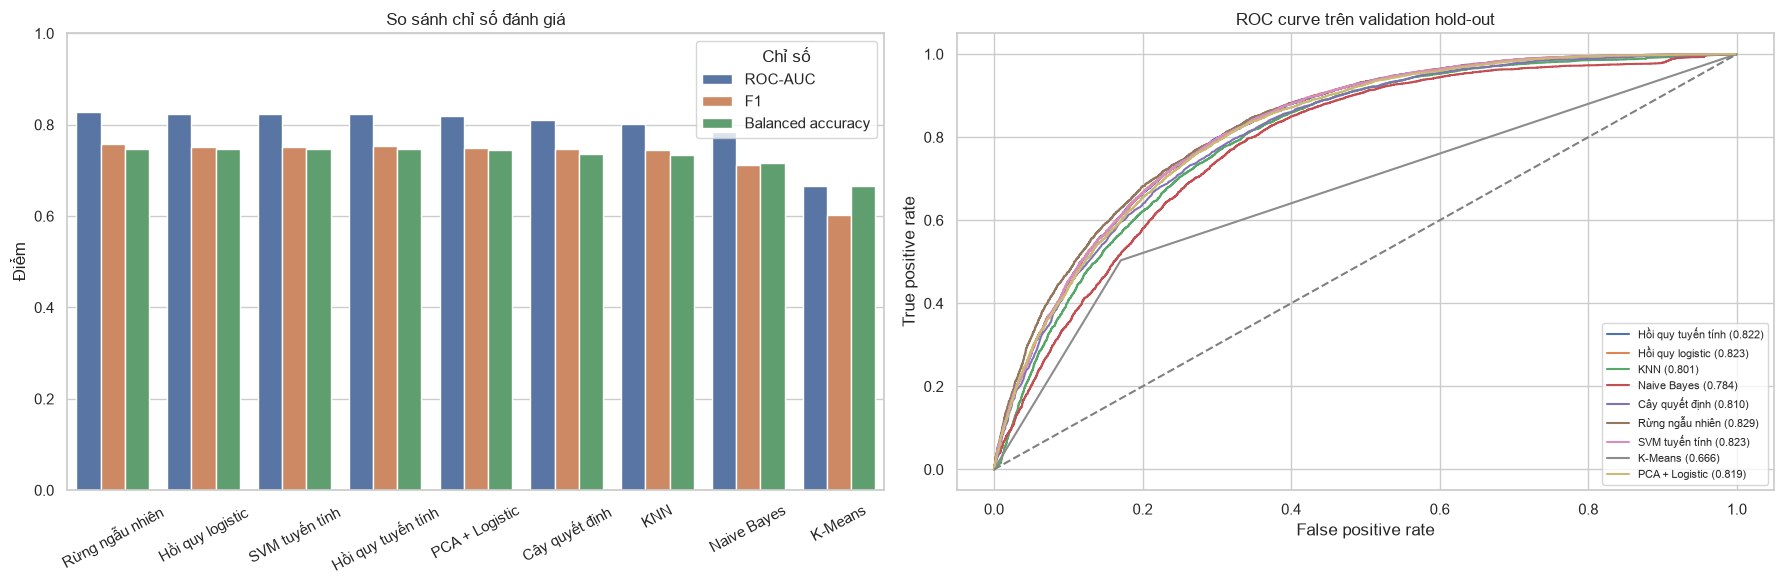

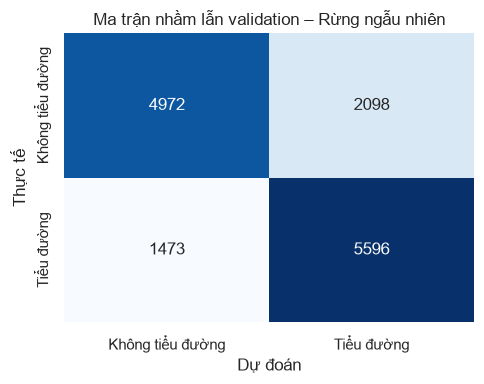

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
plot_data = metrics.melt(id_vars='Mô hình', value_vars=['ROC-AUC', 'F1', 'Balanced accuracy'], var_name='Chỉ số', value_name='Điểm')
sns.barplot(data=plot_data, x='Mô hình', y='Điểm', hue='Chỉ số', ax=axes[0])
axes[0].set_ylim(0, 1); axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=28); axes[0].set_title('So sánh chỉ số đánh giá')
for name, (fpr, tpr, auc) in curves.items(): axes[1].plot(fpr, tpr, label=f'{name} ({auc:.3f})', linewidth=1.5)
axes[1].plot([0, 1], [0, 1], '--', color='gray'); axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve trên validation hold-out'); axes[1].legend(fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig(ARTIFACTS_DIR / 'model_comparison.png', dpi=180); fig.savefig(ARTIFACTS_DIR / 'roc_curves.png', dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_val, best_predictions), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['Không tiểu đường', 'Tiểu đường'], yticklabels=['Không tiểu đường', 'Tiểu đường'])
ax.set(xlabel='Dự đoán', ylabel='Thực tế', title=f'Ma trận nhầm lẫn validation – {winner}'); fig.tight_layout(); fig.savefig(ARTIFACTS_DIR / 'best_confusion_matrix.png', dpi=180); plt.show()

## 5. Lưu mô hình tốt nhất cho web app

Web app sẽ tải hai file bên dưới; không có mã train nào nằm ngoài notebook này.

In [6]:
joblib.dump(best_model, ARTIFACTS_DIR / 'best_diabetes_model.joblib', compress=3)
metrics.to_csv(ARTIFACTS_DIR / 'comparison_metrics.csv', index=False, encoding='utf-8-sig')
full_test_metrics.to_csv(ARTIFACTS_DIR / 'full_brfss_test_metrics.csv', index=False, encoding='utf-8-sig')
metadata = {'model_name': winner, 'selection_metric': 'Validation ROC-AUC', 'feature_names': features, 'test_rows': len(X_test), 'metrics': metrics.iloc[0].to_dict(), 'full_brfss_metrics': full_test_metrics.iloc[0].to_dict(), 'note': 'Chỉ hỗ trợ sàng lọc, không thay thế chẩn đoán y khoa.'}
(ARTIFACTS_DIR / 'model_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu: artifacts/best_diabetes_model.joblib')
print('Đã lưu: artifacts/comparison_metrics.csv, full_brfss_test_metrics.csv và các biểu đồ PNG')

Đã lưu: artifacts/best_diabetes_model.joblib
Đã lưu: artifacts/comparison_metrics.csv, full_brfss_test_metrics.csv và các biểu đồ PNG


## Lưu ý sử dụng

Xác suất trong app là điểm sàng lọc từ mô hình, không phải chẩn đoán bệnh. Kết quả nên được xác nhận bằng tư vấn và xét nghiệm y khoa.